In [16]:

import pandas as pd

df = pd.read_csv('/content/archive (1).zip')

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())


Dataset shape: (1143, 13)

First five rows:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4



Column names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'Id']


In [17]:

# Select all 13 columns, including Id and quality
X = df.copy()

print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Feature names:")
print(X.columns.tolist())

# Standardize all 13 features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nScaled data shape:", X_scaled.shape)


Number of samples: 1143
Number of features: 13
Feature names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'Id']

Scaled data shape: (1143, 13)


In [18]:

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Reduced data shape:", X_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance retained:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")


Reduced data shape: (1143, 2)
Explained variance ratio: [0.25192323 0.17625364]
Total variance retained: 42.82 %


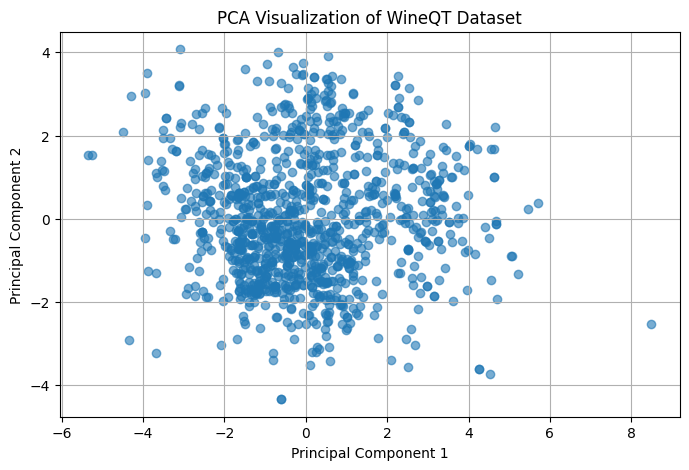

In [19]:

plt.figure(figsize=(8, 5))

plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.6)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of WineQT Dataset")
plt.grid(True)
plt.show()


In [20]:

pca3 = PCA(n_components=3)
X_pca3 = pca3.fit_transform(X_scaled)

print("Features after reduction:", X_pca3.shape[1])
print("Number of samples:", X_pca3.shape[0])
print("Explained variance ratio:", pca3.explained_variance_ratio_)
print("Total variance retained:",
      round(sum(pca3.explained_variance_ratio_) * 100, 2), "%")


Features after reduction: 3
Number of samples: 1143
Explained variance ratio: [0.25192323 0.17625364 0.13093072]
Total variance retained: 55.91 %


In [21]:

pca3 = PCA(n_components=3)
X_pca3 = pca3.fit_transform(X_scaled)

print("Number of features after reduction:", X_pca3.shape[1])
print("Number of samples:", X_pca3.shape[0])

print("Explained variance ratio:", pca3.explained_variance_ratio_)

print("Total variance retained:",
      round(sum(pca3.explained_variance_ratio_) * 100, 2), "%")


Number of features after reduction: 3
Number of samples: 1143
Explained variance ratio: [0.25192323 0.17625364 0.13093072]
Total variance retained: 55.91 %


Question 1: What happens if we change the number of components?
Change PCA(n_components=2) to PCA(n_components=3).

**1. How many features are present after reduction?**

There are 3 principal components after reduction, instead of 2.

**2. Does the number of samples change?**

No, the number of samples remains unchanged at 1,143. PCA reduces the number of features, not the number of samples.

**3. Does the total variance retained increase or decrease?**

The total variance retained increases because the third principal component captures additional variance from the dataset.

In [22]:

# Apply PCA without standardization using all 13 features
pca_original = PCA(n_components=2)
X_pca_original = pca_original.fit_transform(X)

print("Explained variance ratio:",
      pca_original.explained_variance_ratio_)

print("Total variance retained:",
      round(sum(pca_original.explained_variance_ratio_) * 100, 2), "%")


Explained variance ratio: [0.99458208 0.00514068]
Total variance retained: 99.97 %


Question 2: What happens if standardization is removed?
Replace X_scaled with X in the PCA transformation.

**1. Does the explained variance ratio change?**

Yes, the explained variance ratio changes when standardization is removed because PCA now uses the original numerical scales of the features.

**2. Why might features with larger numerical scales influence PCA more strongly?**

Features with larger numerical scales may have greater variance and can dominate the principal components, influencing the PCA results more strongly.

**3. Is standardization always necessary?**

No, standardization is not always necessary. It is generally recommended when features have different scales, but it may not be required when all features have comparable scales.

In [23]:

components = [1, 2, 3, 5, 10]

for n in components:
    pca_test = PCA(n_components=n)
    pca_test.fit(X_scaled)

    variance = sum(pca_test.explained_variance_ratio_) * 100

    print(f"{n} components: {variance:.2f}% variance retained")


1 components: 25.19% variance retained
2 components: 42.82% variance retained
3 components: 55.91% variance retained
5 components: 72.71% variance retained
10 components: 95.85% variance retained


In [24]:

pca_full = PCA()
pca_full.fit(X_scaled)

cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

print("Cumulative explained variance:")

for i, variance in enumerate(cumulative_variance, start=1):
    print(f"{i} components: {variance * 100:.2f}%")

components_90 = np.argmax(cumulative_variance >= 0.90) + 1

print("\nComponents needed for at least 90% variance:",
      components_90)


Cumulative explained variance:
1 components: 25.19%
2 components: 42.82%
3 components: 55.91%
4 components: 65.27%
5 components: 72.71%
6 components: 79.84%
7 components: 84.66%
8 components: 88.96%
9 components: 92.71%
10 components: 95.85%
11 components: 98.24%
12 components: 99.55%
13 components: 100.00%

Components needed for at least 90% variance: 9


Question 3: What happens if we retain more components?
Try 1, 2, 3, 5 and 10 principal components.

**1. How does the cumulative explained variance change?**

Cumulative explained variance increases as the number of principal components increases because more information from the original dataset is retained.

**2. How many components are needed to retain at least 90% of the variance?**

The number of components printed by Step 2 is the minimum required to retain at least 90% of the variance.

**3. Is reducing to two components always the best choice?**

No. Two components are useful for visualizing data, but they may lose important information. More components may be needed to retain at least 90% of the variance.

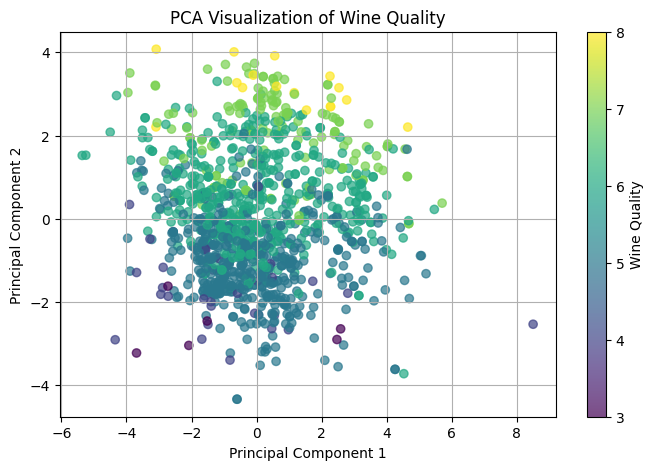

In [25]:

plt.figure(figsize=(8, 5))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df['quality'],
    cmap='viridis',
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Wine Quality")
plt.colorbar(scatter, label="Wine Quality")
plt.grid(True)
plt.show()


Question 4: What happens to the visualization?
Plot the first two principal components and observe the three wine classes.

**1. Are the classes clearly separated?**

The wine quality values are not necessarily clearly separated in the two-dimensional PCA plot. Points with different quality values may overlap.

**2. What information might be lost when reducing 13 features to 2?**

Some information and variation from the original 13 features may be lost because only two principal components are retained.

**3. Does PCA use the class labels to create the components?**

No. PCA is an unsupervised learning technique. It creates components using the input features without using class labels. In our graph, quality is used only to color the points.

In [26]:

# Apply PCA using all 13 standardized features
pca2 = PCA(n_components=2)
pca2.fit(X_scaled)

print("Original features:")
print(X.columns.tolist())

print("\nPrincipal component coefficients:")
print(pca2.components_)

print("\nNumber of original features:", X.shape[1])
print("Number of extracted components:", pca2.n_components_)


Original features:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'Id']

Principal component coefficients:
[[ 0.47750067 -0.22369614  0.44707047  0.16608228  0.21158396 -0.05584784
   0.01369381  0.39503221 -0.41520442  0.23669015 -0.1139593   0.07883684
  -0.20677085]
 [ 0.03207913 -0.38324503  0.19392824 -0.10924891 -0.15183135 -0.19774553
  -0.31130712 -0.29272457  0.02396455  0.16283452  0.49875547  0.49553927
   0.19075973]]

Number of original features: 13
Number of extracted components: 2


Question 5: Does PCA select existing features?

**1. Are the two principal components original Wine dataset columns?**

No. The two principal components are new features created by combining the original 13 columns mathematically.

**2. What is the difference between feature selection and feature extraction?**
- Feature selection: Selects a subset of existing features from the dataset.
- Feature extraction: Transforms existing features into new features.

**3. Why is PCA considered a feature extraction technique?**

PCA is considered a feature extraction technique because it transforms the original features into new principal components that capture the maximum possible variance in the data.